# Notebook 01d — Country of production, by genre, and a United States-only check

Added November 18, 2026 for the law-review manuscript (Part III, the corpus). The September 2026 pipeline audit computed these numbers in scratch code; this notebook puts them in the pipeline. It calls no model and changes nothing upstream. Outputs go to `v4_rebuild/01d_country/`.

**Country rule.** The same rule as the corpus table in Notebook 16a: the CMU corpus's Freebase country field where the film is in CMU and the field is filled, and otherwise the Wikipedia Movie Plots `Origin/Ethnicity` field (American counts as the United States; Bollywood, Tamil, Telugu, Malayalam, Bengali, Marathi, Kannada, Punjabi and Assamese count as India). A film listing the United States among its countries counts as United States; otherwise a film listing India counts as India.

**Part A.** Shares overall and genre by genre.

**Part B.** The two measures recomputed on United States films alone. For each genre, the top 25 narrative features by prevalence and by distinctiveness on the full corpus are compared with the top 25 on United States films only, and the two rankings are correlated over the genre's whole narrative vocabulary. The candidate features are the narrative (feature, type) pairs of the full-corpus table, so only the films change.

In [1]:
import json, shutil, sys, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

try:
    from google.colab import drive  # type: ignore
    drive.mount('/content/drive')
except Exception:
    pass

_CANDS = [
    Path('/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational'),
    Path.home() / 'Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational',
    Path.cwd().parent, Path.cwd().parent.parent, Path.cwd(),
]
_CANDS += [p for p in (Path.home() / 'Library/CloudStorage').glob('GoogleDrive-*/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational')] if (Path.home() / 'Library/CloudStorage').exists() else []
PROJECT_ROOT = next(c for c in _CANDS if (c / 'Analysis' / 'v4_rebuild').exists())
sys.path.insert(0, str(PROJECT_ROOT / 'Analysis' / 'notebooks'))
import saf_style as S
S.use()
V4 = PROJECT_ROOT / 'Analysis' / 'v4_rebuild'
DATA = PROJECT_ROOT / 'Data'
OUT = V4 / '01d_country'
OUT.mkdir(parents=True, exist_ok=True)
TMP = Path(tempfile.mkdtemp())
def read_parquet(p, **kw):
    local = TMP / p.name          # Drive sometimes serves partial parquet files; read a local copy
    shutil.copy(p, local)
    return pd.read_parquet(local, **kw)

TOP_K = 25
ALPHA = 1.0
report = []
def out(s=''):
    print(s); report.append(s)
out('NOTEBOOK 01d — COUNTRY OF PRODUCTION AND A UNITED STATES-ONLY CHECK')

NOTEBOOK 01d — COUNTRY OF PRODUCTION AND A UNITED STATES-ONLY CHECK


## Assign a country to every film (the Notebook 16a rule)

In [2]:
U = read_parquet(V4 / '01c_union' / 'movies_union.parquet',
                 columns=['union_id', 'cmu_wiki_id', 'kaggle_wiki_id', 'genres_canonical'])
U['genres'] = U['genres_canonical'].map(lambda g: [str(x) for x in list(g)] if g is not None else [])
cmu = pd.read_csv(DATA / 'MovieSummaries' / 'movie.metadata.tsv', sep='\t', header=None,
                  names=['wid', 'fbid', 'name', 'date', 'rev', 'runtime', 'langs', 'countries', 'genres'])
cmu['countries'] = cmu['countries'].apply(lambda s: list(json.loads(s).values()) if isinstance(s, str) else [])
cmu_c = dict(zip(cmu['wid'].astype(str), cmu['countries']))
kag = pd.read_csv(DATA / 'WikipediaMoviePlots' / 'wiki_movie_plots_deduped.csv')
kag['slug'] = kag['Wiki Page'].str.rsplit('/', n=1).str[-1]
kag_o = dict(zip(kag['slug'], kag['Origin/Ethnicity']))
INDIA = {'Bollywood', 'Tamil', 'Telugu', 'Malayalam', 'Bengali', 'Marathi', 'Kannada', 'Punjabi', 'Assamese'}
def country(r):
    cs = cmu_c.get(str(r.cmu_wiki_id), []) if pd.notna(r.cmu_wiki_id) else []
    if cs:
        return 'US' if 'United States of America' in cs else ('India' if 'India' in cs else 'other')
    o = kag_o.get(r.kaggle_wiki_id) if isinstance(r.kaggle_wiki_id, str) else None
    if o is None: return 'unknown'
    return 'US' if o == 'American' else ('India' if o in INDIA else 'other')
U['country'] = [country(r) for r in U.itertuples()]

## Part A. Shares overall and by genre

In [3]:
cs = U['country'].value_counts()
N = len(U)
out(f'{N:,} films')
for k in ['US', 'India', 'other', 'unknown']:
    out(f'  {k:8s} {cs.get(k, 0):6,}  {100 * cs.get(k, 0) / N:5.1f}%')
G = U[['union_id', 'country', 'genres']].explode('genres').dropna(subset=['genres'])
by_genre = (pd.crosstab(G['genres'], G['country'], normalize='index') * 100).round(1)
by_genre['films'] = G.groupby('genres').size()
by_genre = by_genre[['films', 'US', 'India', 'other', 'unknown']].sort_values('India', ascending=False)
by_genre.to_csv(OUT / 'country_share_by_genre.csv')
out(''); out('Share of each genre\'s films by country (percent)')
out(by_genre.to_string())

45,958 films
  US       23,308   50.7%
  India     7,167   15.6%
  other    13,628   29.7%
  unknown   1,855    4.0%

Share of each genre's films by country (percent)
country          films    US  India  other  unknown
genres                                             
Music             2926  48.0   32.4   16.5      3.1
Romance           8220  43.4   27.7   26.6      2.4
Action            7775  49.9   21.6   25.6      2.9
Drama            22364  46.1   18.1   32.8      3.0
Thriller          7447  57.3   13.8   26.7      2.2
Family            4164  65.4   12.3   15.1      7.1
Comedy           14724  58.1   11.2   26.8      4.0
Crime             5564  60.7    8.6   29.0      1.6
Fantasy           2429  56.4    6.8   33.7      3.2
History           2882  57.3    5.2   35.6      1.9
Mystery           2681  69.5    4.7   24.1      1.6
Horror            4363  59.5    4.6   32.2      3.7
Adventure         6146  67.7    4.5   26.3      1.6
War               1658  52.8    2.5   42.9      1.8
S

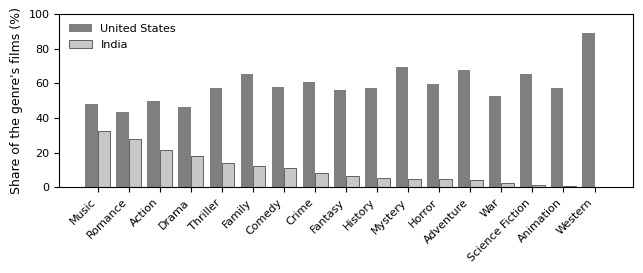

In [4]:
fig, ax = plt.subplots(figsize=S.size(1.0, 2.8))
x = np.arange(len(by_genre))
ax.bar(x - 0.2, by_genre['US'], width=0.4, color=S.NEUTRAL, label='United States')
ax.bar(x + 0.2, by_genre['India'], width=0.4, color=S.LIGHT, edgecolor=S.INK, linewidth=0.4, label='India')
ax.set_xticks(x); ax.set_xticklabels(by_genre.index, rotation=45, ha='right')
ax.set_ylabel('Share of the genre\'s films (%)'); ax.set_ylim(0, 100); ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / 'country_share_by_genre.png', dpi=300, facecolor='white')
plt.show()

## Part B. The two measures on United States films only

Prevalence is the share of a genre's films that contain the feature. Distinctiveness is the smoothed share of the films containing the feature that belong to the genre, with one pseudo-observation divided among the genres in proportion to each genre's share of film-genre pairs, as in Notebook 03; here every count is taken over the chosen set of films.

In [5]:
cls = read_parquet(V4 / '03b_classification' / 'stockiness_long_classified.parquet',
                   columns=['element', 'element_type', 'genre', 'is_narrative_element'])
narr = cls[cls['is_narrative_element']][['element', 'element_type', 'genre']]
pairs = narr[['element', 'element_type']].drop_duplicates()
idx = read_parquet(V4 / '02_elements' / 'element_index.parquet').drop_duplicates()
idx = idx.merge(pairs, on=['element', 'element_type'])
FG = U[['union_id', 'country', 'genres']].explode('genres').dropna(subset=['genres']).rename(columns={'genres': 'genre'})

def measures(film_ids):
    fg = FG[FG['union_id'].isin(film_ids)]
    n_g = fg.groupby('genre').size()
    p_g = n_g / n_g.sum()
    ix = idx[idx['union_id'].isin(film_ids)]
    f_e = ix.groupby(['element', 'element_type'])['union_id'].nunique().rename('f_e')
    eg = ix.merge(fg, on='union_id').groupby(['element', 'element_type', 'genre'])['union_id'].nunique().rename('f_eg').reset_index()
    m = narr.merge(eg, on=['element', 'element_type', 'genre'], how='left').fillna({'f_eg': 0})
    m = m.merge(f_e.reset_index(), on=['element', 'element_type'], how='left').fillna({'f_e': 0})
    m['prevalence'] = m['f_eg'] / m['genre'].map(n_g)
    m['distinctiveness'] = (m['f_eg'] + ALPHA * m['genre'].map(p_g)) / (m['f_e'] + ALPHA)
    return m

full = measures(set(U['union_id']))
us = measures(set(U.loc[U['country'] == 'US', 'union_id']))
key = ['element', 'element_type', 'genre']
both = full.merge(us, on=key, suffixes=('_full', '_us'))
rows = []
for g, d in both.groupby('genre'):
    r = {'genre': g, 'us_films': int((FG['genre'].eq(g) & FG['country'].eq('US')).sum())}
    for m in ['prevalence', 'distinctiveness']:
        top_full = set(d.nlargest(TOP_K, f'{m}_full').index)
        top_us = set(d.nlargest(TOP_K, f'{m}_us').index)
        r[f'{m}_top{TOP_K}_kept'] = len(top_full & top_us)
        r[f'{m}_spearman'] = round(spearmanr(d[f'{m}_full'], d[f'{m}_us']).correlation, 3)
    rows.append(r)
rob = pd.DataFrame(rows).set_index('genre')
rob.to_csv(OUT / 'us_only_robustness.csv')
out(''); out(f'United States films only: top {TOP_K} kept out of {TOP_K}, and rank correlation over the narrative vocabulary')
out(rob.to_string())
for m in ['prevalence', 'distinctiveness']:
    k = rob[f'{m}_top{TOP_K}_kept']
    out(f'{m}: top {TOP_K} kept {k.min()} to {k.max()} (median {k.median():.0f}); '
        f'Spearman {rob[m + "_spearman"].min():.2f} to {rob[m + "_spearman"].max():.2f}; '
        f'lowest in {", ".join(k.nsmallest(2).index)}')


United States films only: top 25 kept out of 25, and rank correlation over the narrative vocabulary
                 us_films  prevalence_top25_kept  prevalence_spearman  distinctiveness_top25_kept  distinctiveness_spearman
genre                                                                                                                      
Action               3879                     21                0.897                           8                     0.790
Adventure            4158                     24                0.955                           8                     0.854
Animation            1633                     23                0.903                          12                     0.757
Comedy               8550                     23                0.939                           9                     0.844
Crime                3380                     24                0.920                           9                     0.790
Drama               10308      

In [6]:
(OUT / 'country_report.txt').write_text('\n'.join(report) + '\n')
print('wrote', OUT)

wrote /Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild/01d_country
